# Simulation to solve a real problem - The Supreme Court

> This page is adapted from [Brett, Rush, Adhikari, Denero and Wagner (2023)](https://odsti.github.io/cfd-textbook/reply_supreme.html). See the [license](https://github.com/pxr687/Intro_Comp_Programming/blob/main/license.md) page for more information

Her is a real, serious problem:

> In 1963, a court in Talladega County, Alabama sentenced a young black man called Robert Swain to death [1](https://en.wikipedia.org/wiki/Furman_v._Georgia). All 12 jurors in his trial were white. He appealed his sentence, citing, among other factors, evidence of bias in the process by which his jury was selected. At the time, only men aged 21 or older were allowed to serve on juries in Talladega County. In the county, 26% of the eligible jurors were black. (Quote from [here](https://odsti.github.io/cfd-textbook/sampling_problem.html)).

His trial jury of 12 people had no Black members.

The local population of people who could be jurors was 26% Black.

If the jury had been representative of the whole population, we would expect about 26 of 100 people to
be Black.  That's around 1 in 4 (25%), so we would expect about one in four
jurors to be Black - so around 3 of 12.

The Supreme Court was not convinced that there was evidence of systematic bias.  But, to start with the jurors - is it surprising that we expected around 3 Black jurors, but we got 0.  Is the value 0 surprising, if each juror has 26% chance of being Black?

To answer this, we are going to go through a couple of steps.

The first is to build an *ideal model* of the world, where it *is true* that
each juror has a 26% of being Black.  We sometimes call this our *ideal world*.
If you are used to statistical terms, this ideal model is our *null
hypothesis*.

Then we can *simulate* making many juries in this ideal world.

Finally we ask whether our simulated juries, from the ideal world, often give
us a count of zero Black jurors.  If they don't, then we can say that we are
*surprised* by the value of 0, if the jury did arise from that real world.  If
the value 0 is sufficiently unusual, we become suspicious that the real world
is rather different from our ideal world.  We consider *rejecting* the ideal
world as a good model of the real world.

## The ideal world

Our *ideal model* (or null hypothesis) is a world where each juror has been
truly randomly selected from the eligible population. That is, for any one
juror, there is a 0.26 probability that they are Black.

## Simulations with the ideal model

To do a *simulation* with this ideal model, we will start by making one jury,
of 12 people, where it is really true that each juror has a 26% of being Black.
Not to pun, but we will call one simulation of a jury of 12 - *one trial*.

Then we simulate 10 juries of 12 people (do 10 trials), to get warmed up.

Finally we make 10000 juries, each of 12 people, and see what we get.

In [1]:
# Import the array library
import numpy as np

Here we use `np.random.choice()` to simulate one
jury, and count the number of Black people in the simulated jury.

In [2]:
# Choose 12 jurors, where "Black" has probability 0.26
jurors = np.random.choice([1, 0], 
                          p=[0.26, 0.74],
                          size=12)
# np.count_nonzero counts the number of 1 values:
np.count_nonzero(jurors)

np.int64(4)

That is one estimate, for the number of Black people we can expect, if our
model is correct.  Call this one *trial*. We can run that a few times to get a
range of values.   If we run it only a few times, we might be unlucky, and get
some results that are not representative.  It is safer to run it a huge number
of times, to make sure we've got an idea of the variation.

To start with, we will run 10 trials.

We get ready to store the results of each estimate.

In [3]:
# Make an array of 10 zeros, to store the results.
counts = np.zeros(10)

We repeat the code from the cell above, but now, we store each trial result
(count) in the `counts` array:

In [4]:
jurors = rng.choice([1, 0], p=[0.26, 0.74], size=12)
count = np.count_nonzero(jurors)
counts[0] = count
counts

NameError: name 'rng' is not defined

Run the cell above a few times, perhaps with Control-Enter, to see the first value in the `counts` array changing.

Now we collect the result of 10 trials, by using a for loop.


In [6]:
# Make a new counts array of zeros to store the results.
counts = np.zeros(10)
for i in np.arange(10):
    # This code is the same as the cell above, but indented,
    # so we run it all, for each time through the for loop.
    jurors =  np.random.choice([1, 0], 
                          p=[0.26, 0.74],
                          size=12)
    count = np.count_nonzero(jurors)
    # Store the result at position i
    counts[i] = count
counts

array([3., 3., 6., 4., 4., 2., 4., 1., 5., 4.])

Each of these values is one estimate for how many Black jurors we should
expect, if our model is right.  Already we get the feeling that 0 is rather
unlikely, if our model is correct.  But - how unlikely?

To get a better estimate, let us do the same thing, but with 10000 juries, and
therefore, 10000 estimates.

In [7]:
# Make a new counts array of zeros to store the results.
counts = np.zeros(10000)
for i in np.arange(10000):
    # This code is the same as the cell above, but indented,
    # so we run it all, for each time through the for loop.
    jurors =  np.random.choice([1, 0], 
                          p=[0.26, 0.74],
                          size=12)
    count = np.count_nonzero(jurors)
    # Store the result at position i
    counts[i] = count
counts

array([5., 4., 1., ..., 3., 3., 5.], shape=(10000,))

If you ran this cell yourself, you will notice that it runs very fast, in much
less than a second, on any reasonable computer.

We now have 10000 estimates, one for each row in the original array, and
therefore, one for each simulated jury.

Remember, the function `len` shows us the length of the array, and therefore,
the number of values in this one-dimensional array.

In [8]:
len(counts)

10000

Next we want to have a look at the spread of these values.  To do this, we plot
a histogram.  Here is how to do that, in Python.  Don't worry about the details, we will go into this more soon.

In [9]:
# Import `matplotlib`.
import matplotlib.pyplot as plt

Now show the histogram.  Don't worry about the details of this command.

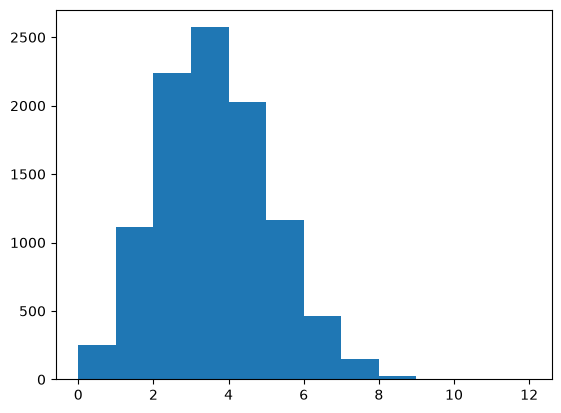

In [11]:
# Do the histogram of our 10000 estimates.
plt.hist(counts, bins=np.arange(13));

The histogram above is called the *sampling distribution*.  The sampling distribution is the distribution of thing we are interested in (the number of Black jurors) given the ideal model, of completely random selection of jurors from a 26% Black population.

It looks as if 0 is a relatively uncommon value among our simulations. How many
times did we get a value of 0, in all our 10000 estimates?

In [12]:
counts_of_0 = counts == 0
n_zeros = np.count_nonzero(counts_of_0)
n_zeros

np.int64(248)

What *proportion* of jury simulations give a value of 0?  We just divide the
number of times we see 0 by the number trials we made:

In [13]:
p = n_zeros / 10000
p

np.float64(0.0248)

We have run an analysis assuming that the jurors were selected at random.  On
that assumption, a count of 0 jurors in 12 is fairly uncommon, in the sense
that the proportion of times we see that result is:

In [14]:
p

np.float64(0.0248)

In other words, our *estimate* of the *probability* of getting 0 Black people
in a jury of 12, is

In [15]:
p

np.float64(0.0248)

What can we conclude?  Only this: that in our ideal model world, where each
juror has a 26% chance of being Black, 0 is uncommon.  This surprising result,
of 0, gives us some cause to wonder if our ideal model of the world is wrong.
One way it could be wrong, is if there was bias in jury selection, so it was
not true that each juror had a 26% of being Black.